# Predicting Airline Satisfaction

**Author:** Mike Johnson <br>
**Date Created:** 2026-10-04 <br>
**Last Updated:** 2026-10-04 <br>
**Objective:** Predicting Airline Satisfaction. <br>
**Data Sources:** https://www.kaggle.com/competitions/playground-series-s6e10 <br>

***

## 1.0 Setup & Configuration

### 1.1 Import Libraries

In [1]:
# Standard libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import kagglehub
import time

# Model selection / evaluation
from sklearn.model_selection import train_test_split, cross_val_score, cross_validate, StratifiedKFold
from sklearn.metrics import (
    roc_auc_score, roc_curve, RocCurveDisplay,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)
import optuna

# Preprocessing / pipeline helpers
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Models
from sklearn.linear_model import LogisticRegression
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

### 1.2 Configuration

In [2]:
RANDOM_STATE = 206
DEV_SIZE = 0.2
TARGET_COL = 'satisfaction'
KAGGLE_PATH = 'playground-series-s6e10'
DATA_PATH = '../data/'
OUTPUT_PATH = '../submissions/'

## 2.0 Data Loading & Structural Inspection

In [3]:
# Download dataset via kagglehub
path = kagglehub.competition_download(
    KAGGLE_PATH, 
    output_dir = DATA_PATH,
    force_download = True)

print("Path to competition files:", path)

100%|██████████| 15.1M/15.1M [00:01<00:00, 15.1MB/s]

Extracting files...


Path to competition files: ../data/


### 2.1 Training Set

In [4]:
# Load training set
train = pd.read_csv(f'{DATA_PATH}train.csv', index_col = 'id')

print(f'Shape: {train.shape}')
train.head()

Shape: (699635, 22)


,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
id,,,,,,,,,,,,,,,,,,,,,
0,36,694,4,4,4,3,1,4,1,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,56,651,5,5,5,5,5,4,4,5,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,31,1371,3,4,2,5,3,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,10,1616,3,5,3,3,3,3,3,3,...,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,23,481,3,4,3,4,5,3,5,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


In [5]:
# Convert target column to binary
train[TARGET_COL] = train[TARGET_COL].map({True: 1, False: 0})

In [6]:
# Get info
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 699635 entries, 0 to 699634
Data columns (total 22 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Age                                699635 non-null  int64  
 1   Flight Distance                    699635 non-null  int64  
 2   Inflight wifi service              699635 non-null  int64  
 3   Departure/Arrival time convenient  699635 non-null  int64  
 4   Ease of Online booking             699635 non-null  int64  
 5   Gate location                      699635 non-null  int64  
 6   Food and drink                     699635 non-null  int64  
 7   Online boarding                    699635 non-null  int64  
 8   Seat comfort                       699635 non-null  int64  
 9   Inflight entertainment             699635 non-null  int64  
 10  On-board service                   699635 non-null  int64  
 11  Leg room service                   699635 non-null

In [7]:
# Describe training set
train.describe(include = 'all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,699635.0,NaN,NaN,NaN,39.001928,13.800943,7.0,27.0,40.0,50.0,85.0
Flight Distance,699635.0,NaN,NaN,NaN,1353.778702,954.422566,67.0,631.0,954.0,1814.0,4983.0
Inflight wifi service,699635.0,NaN,NaN,NaN,2.778722,1.280419,0.0,2.0,3.0,4.0,5.0
Departure/Arrival time convenient,699635.0,NaN,NaN,NaN,3.15621,1.47539,0.0,2.0,3.0,4.0,5.0
Ease of Online booking,699635.0,NaN,NaN,NaN,2.81324,1.32955,0.0,2.0,3.0,4.0,5.0
Gate location,699635.0,NaN,NaN,NaN,3.013734,1.254014,0.0,2.0,3.0,4.0,5.0
Food and drink,699635.0,NaN,NaN,NaN,3.265644,1.300202,0.0,2.0,3.0,4.0,5.0
Online boarding,699635.0,NaN,NaN,NaN,3.364156,1.288538,0.0,2.0,4.0,4.0,5.0
Seat comfort,699635.0,NaN,NaN,NaN,3.56895,1.275333,0.0,3.0,4.0,5.0,5.0
Inflight entertainment,699635.0,NaN,NaN,NaN,3.45391,1.308157,0.0,2.0,4.0,5.0,5.0


### 2.2 Test Set

In [8]:
# Load test set
test = pd.read_csv(f'{DATA_PATH}test.csv', index_col = 'id')

print(f'Shape: {test.shape}')
test.head()

Shape: (299844, 21)


,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,...,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class
id,,,,,,,,,,,,,,,,,,,,,
699635,25,1197,4,4,4,2,3,4,3,3,...,5,2,1,3,0,0.0,Female,disloyal Customer,Business travel,Eco
699636,36,829,5,5,5,5,5,4,5,5,...,2,4,3,5,0,0.0,Male,Loyal Customer,Business travel,Eco
699637,45,472,4,5,5,5,4,4,4,4,...,3,1,3,4,0,0.0,Male,Loyal Customer,Business travel,Eco
699638,45,762,2,2,2,5,3,2,3,3,...,4,4,4,3,0,0.0,Female,disloyal Customer,Business travel,Business
699639,34,594,1,2,1,1,2,1,2,2,...,4,2,1,2,0,0.0,Male,Loyal Customer,Personal Travel,Eco Plus


In [9]:
# Get info
test.info()

<class 'pandas.DataFrame'>
RangeIndex: 299844 entries, 699635 to 999478
Data columns (total 21 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Age                                299844 non-null  int64  
 1   Flight Distance                    299844 non-null  int64  
 2   Inflight wifi service              299844 non-null  int64  
 3   Departure/Arrival time convenient  299844 non-null  int64  
 4   Ease of Online booking             299844 non-null  int64  
 5   Gate location                      299844 non-null  int64  
 6   Food and drink                     299844 non-null  int64  
 7   Online boarding                    299844 non-null  int64  
 8   Seat comfort                       299844 non-null  int64  
 9   Inflight entertainment             299844 non-null  int64  
 10  On-board service                   299844 non-null  int64  
 11  Leg room service                   299844 non

In [10]:
# Describe test set
test.describe(include = 'all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,299844.0,NaN,NaN,NaN,38.993036,13.785915,7.0,27.0,40.0,50.0,85.0
Flight Distance,299844.0,NaN,NaN,NaN,1353.368922,953.547614,67.0,631.0,954.0,1814.0,4983.0
Inflight wifi service,299844.0,NaN,NaN,NaN,2.776587,1.280959,0.0,2.0,3.0,4.0,5.0
Departure/Arrival time convenient,299844.0,NaN,NaN,NaN,3.151595,1.474528,0.0,2.0,3.0,4.0,5.0
Ease of Online booking,299844.0,NaN,NaN,NaN,2.812563,1.329513,0.0,2.0,3.0,4.0,5.0
Gate location,299844.0,NaN,NaN,NaN,3.013117,1.254385,0.0,2.0,3.0,4.0,5.0
Food and drink,299844.0,NaN,NaN,NaN,3.270034,1.300376,0.0,2.0,3.0,4.0,5.0
Online boarding,299844.0,NaN,NaN,NaN,3.365707,1.2869,0.0,2.0,4.0,4.0,5.0
Seat comfort,299844.0,NaN,NaN,NaN,3.572121,1.275585,0.0,3.0,4.0,5.0,5.0
Inflight entertainment,299844.0,NaN,NaN,NaN,3.456007,1.309455,0.0,2.0,4.0,5.0,5.0


## 3.0 Train/Dev Split

In [11]:
# Define X and y columns
X = train.drop(columns=[TARGET_COL])
y = train[TARGET_COL]

In [12]:
# Create train and dev sets
X_train, X_dev, y_train, y_dev = train_test_split(
    X, y, 
    test_size = DEV_SIZE, 
    random_state = RANDOM_STATE,
    stratify = y
)

print(f"Train: {X_train.shape}, Dev: {X_dev.shape}, Test: {test.shape}")

Train: (559708, 21), Dev: (139927, 21), Test: (299844, 21)


## 4.0 Exploratory Analysis

In [13]:
# Create dataframe for eda
eda = train[train.index.isin(X_train.index)]

### 4.1 Target Variable Analysis

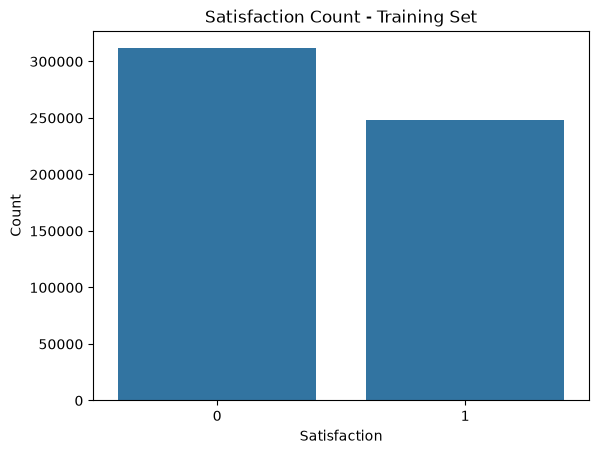

In [14]:
# Visualize counts of target variable
sns.countplot(eda, x = TARGET_COL,)
plt.title('Satisfaction Count - Training Set')
plt.xlabel('Satisfaction')
plt.ylabel('Count')

plt.show()

### 4.2 Numerical Features

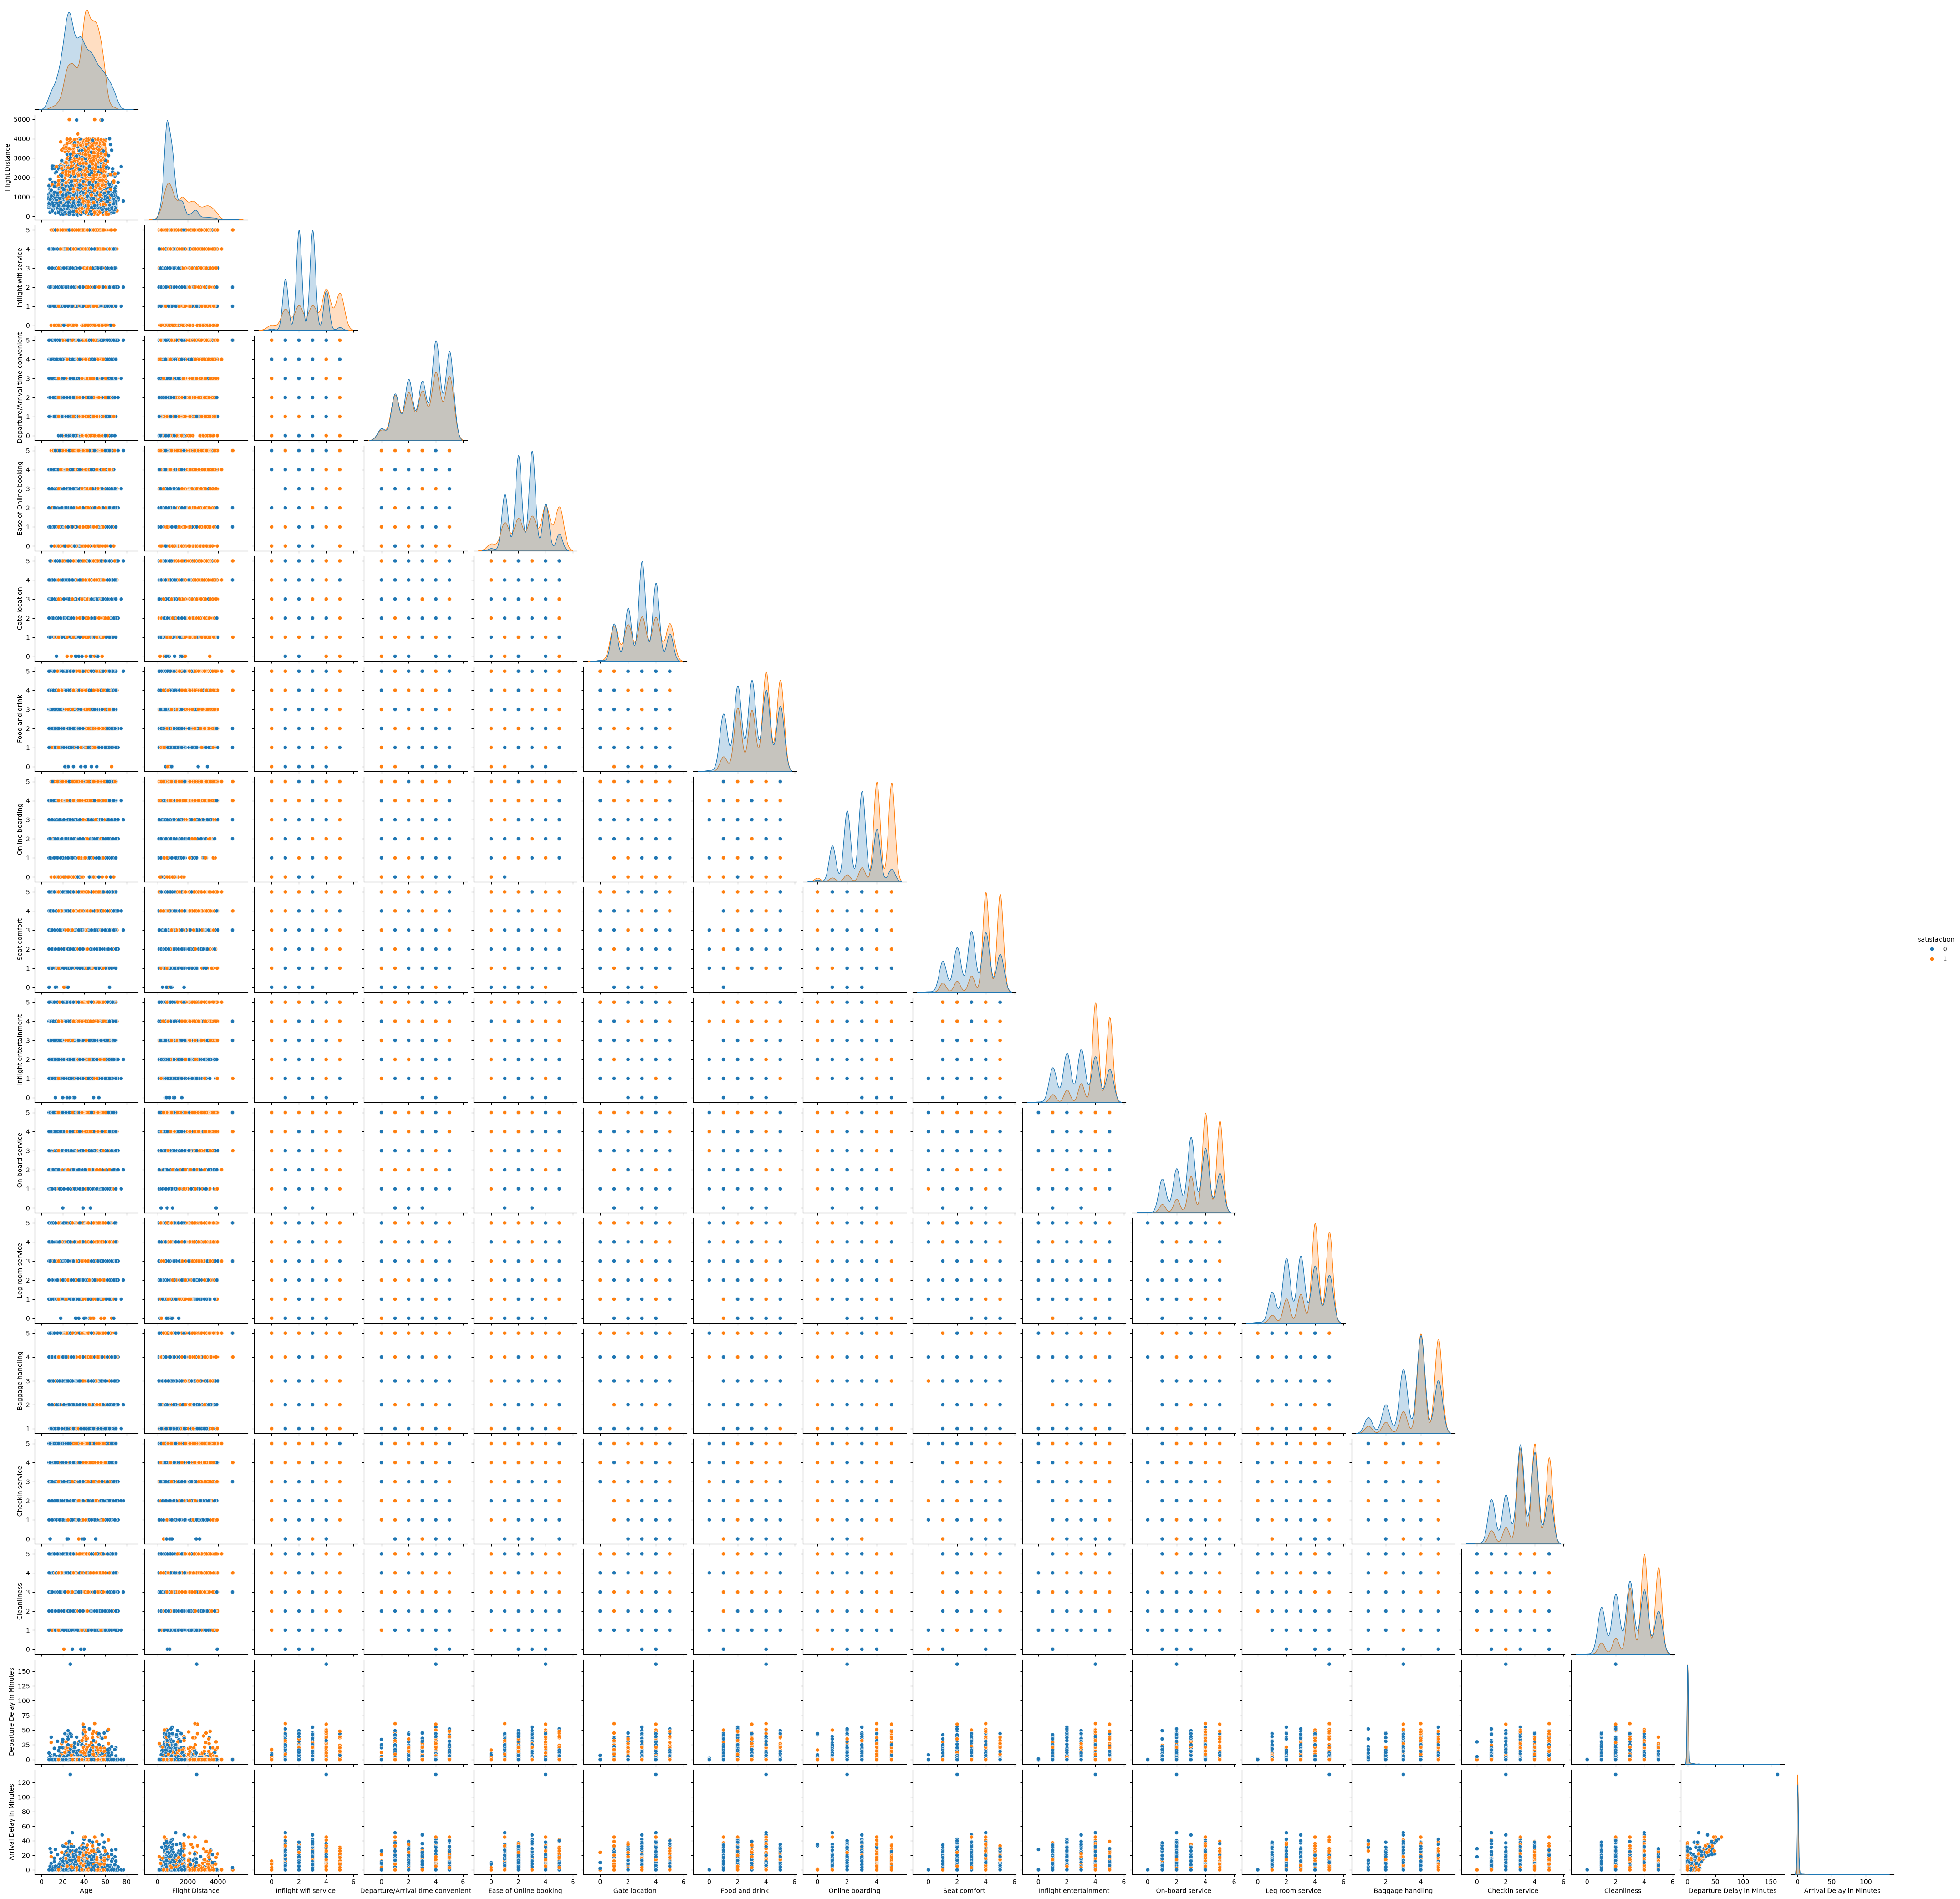

In [15]:
# Paiplot of numerical features
sns.pairplot(
    eda.sample(n = 5000, random_state = RANDOM_STATE),
    hue = TARGET_COL,
    corner = True
)

plt.show()

### 4.3 Categorical Features

In [16]:
# Define categorical columns
categorical_features = eda.select_dtypes(include=['str']).columns.to_list()

def cat_by(col):
    return eda.groupby(col)[TARGET_COL].mean()

for col in categorical_features:
    print(f"\n--- {col} ---")
    rates = cat_by(col)
    print(rates.map(lambda x: f"{x:.0%}"))


--- Gender ---
Gender
Female    44%
Male      45%
Name: satisfaction, dtype: str

--- Customer Type ---
Customer Type
Loyal Customer       50%
disloyal Customer    20%
Name: satisfaction, dtype: str

--- Type of Travel ---
Type of Travel
Business travel    58%
Personal Travel    10%
Name: satisfaction, dtype: str

--- Class ---
Class
Business    73%
Eco         17%
Eco Plus    24%
Name: satisfaction, dtype: str


### 4.4 Missing Values

In [17]:
missing = X_train.isnull().mean().sort_values(ascending=False)
missing[missing > 0].round(2) * 100

Arrival Delay in Minutes    0.0
dtype: float64

## 5.0 Preprocessing

In [18]:
# Define column groups
numeric_features = X_train.select_dtypes(include=['float']).columns.to_list()
categorical_features = X_train.select_dtypes(include=['str']).columns.to_list()

In [19]:
# Impute median for missing values
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

In [20]:
# One-hot encode categorical features
categorical_transformer = Pipeline([
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

In [21]:
# Combine numeric and categorical steps into a single preprocessor
preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
], remainder = 'passthrough')

In [22]:
# Function to make model pipeline
def make_pipeline(model, scale=False):
    """Wrap a model in the preprocessing pipeline."""
    steps = [('preprocessor', preprocessor)]
    if scale:
        steps.append(('scaler', StandardScaler()))
    steps.append(('model', model))
    return Pipeline(steps)

## 6.0 Modeling

In [23]:
# Store fitted models and their dev scores for later comparison
models = {}
results = {}


def evaluate(name, model):
    """Fit on the training set, score ROC-AUC on the dev set, record the result,
    and visualize the ROC curve, confusion matrix, and classification report.
    """
    start = time.perf_counter()

    model.fit(X_train, y_train)

    # Predicted probabilities for the positive class (needed for ROC-AUC)
    proba = model.predict_proba(X_dev)[:, 1]
    preds = model.predict(X_dev)

    roc_auc = roc_auc_score(y_dev, proba)
    elapsed = time.perf_counter() - start

    models[name] = model
    results[name] = {'ROC_AUC': roc_auc, 'fit_seconds': elapsed}
    print(f'{name:<22} ROC-AUC = {roc_auc:.4f}   ({elapsed:.1f}s)')
    print(f'\nClassification Report — {name}:')
    print(classification_report(y_dev, preds))

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # ROC curve
    fpr, tpr, _ = roc_curve(y_dev, proba)
    axes[0].plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.3f})')
    axes[0].plot([0, 1], [0, 1], color='red', linestyle='--', linewidth=1, label='Chance')
    axes[0].set_xlabel('False Positive Rate')
    axes[0].set_ylabel('True Positive Rate')
    axes[0].set_title(f'{name}: ROC Curve')
    axes[0].legend(loc='lower right')

    # Confusion matrix
    cm = confusion_matrix(y_dev, preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(ax=axes[1], cmap='Blues', colorbar=False)
    axes[1].set_title(f'{name}: Confusion Matrix')

    plt.tight_layout()
    plt.show()

    return model

### 6.1 Model Training

#### 6.1.1 Logistic Regression

Logistic Regression    ROC-AUC = 0.9220   (0.6s)

Classification Report — Logistic Regression:
              precision    recall  f1-score   support

           0       0.89      0.88      0.89     77859
           1       0.85      0.87      0.86     62068

    accuracy                           0.87    139927
   macro avg       0.87      0.87      0.87    139927
weighted avg       0.87      0.87      0.87    139927



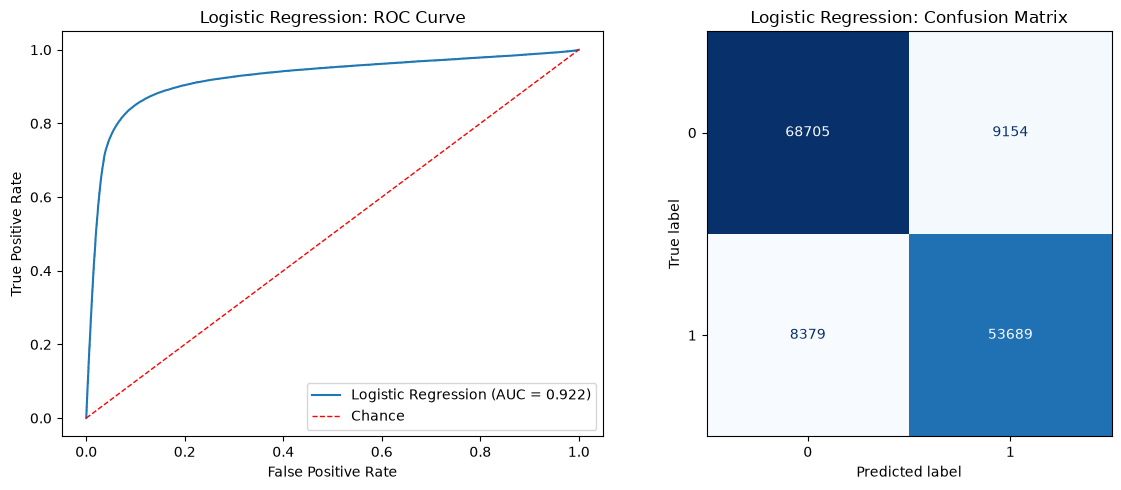

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['Age','Flight Distance','Inflight wifi service',...,'Customer Type', 'Type of Travel','Class']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,21
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``r

In [24]:
evaluate('Logistic Regression', make_pipeline(
    LogisticRegression(
        class_weight = 'balanced',
        max_iter = 2000,
        random_state = RANDOM_STATE
    ),
    scale=True
))

#### 6.1.2 LightGBM

LightGBM               ROC-AUC = 0.9583   (4.1s)

Classification Report — LightGBM:
              precision    recall  f1-score   support

           0       0.93      0.94      0.93     77859
           1       0.93      0.90      0.92     62068

    accuracy                           0.93    139927
   macro avg       0.93      0.92      0.92    139927
weighted avg       0.93      0.93      0.93    139927



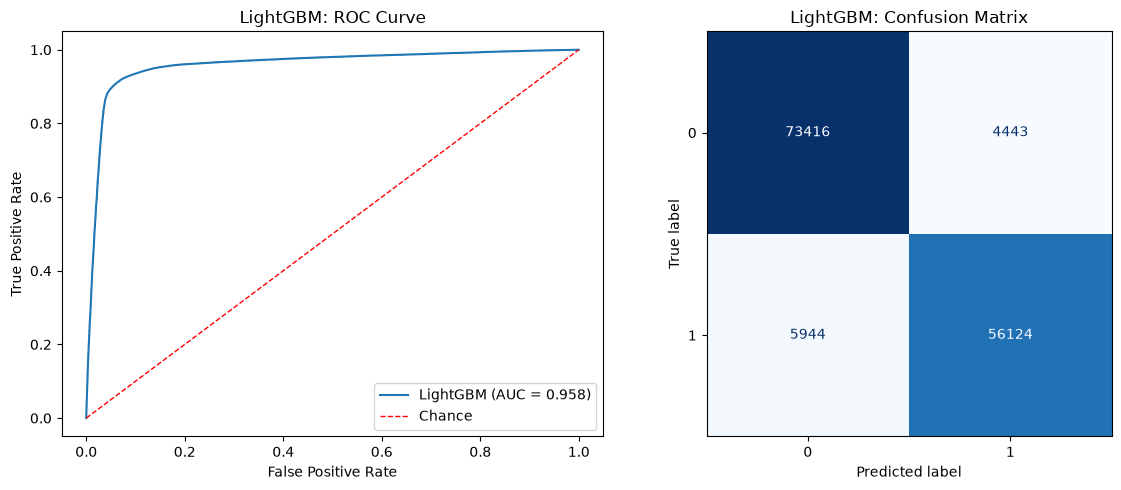

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['Age','Flight Distance','Inflight wifi service',...,'Customer Type', 'Type of Travel','Class']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,21
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remaind

In [25]:
evaluate('LightGBM', make_pipeline(
    LGBMClassifier(
        n_estimators=1000,
        learning_rate=0.03,
        num_leaves=31,
        max_depth=-1,
        min_child_samples=20,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=0.1,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=-1
    )
))

#### 6.1.3 CatBoost

0:	total: 64ms	remaining: 1m 3s
100:	total: 1.29s	remaining: 11.5s
200:	total: 2.62s	remaining: 10.4s
300:	total: 3.9s	remaining: 9.05s
400:	total: 5.17s	remaining: 7.72s
500:	total: 6.44s	remaining: 6.42s
600:	total: 7.72s	remaining: 5.12s
700:	total: 8.99s	remaining: 3.83s
800:	total: 10.3s	remaining: 2.55s
900:	total: 11.5s	remaining: 1.26s
999:	total: 12.7s	remaining: 0us
CatBoost               ROC-AUC = 0.9584   (13.2s)

Classification Report — CatBoost:
              precision    recall  f1-score   support

           0       0.93      0.94      0.93     77859
           1       0.93      0.90      0.92     62068

    accuracy                           0.93    139927
   macro avg       0.93      0.92      0.92    139927
weighted avg       0.93      0.93      0.93    139927



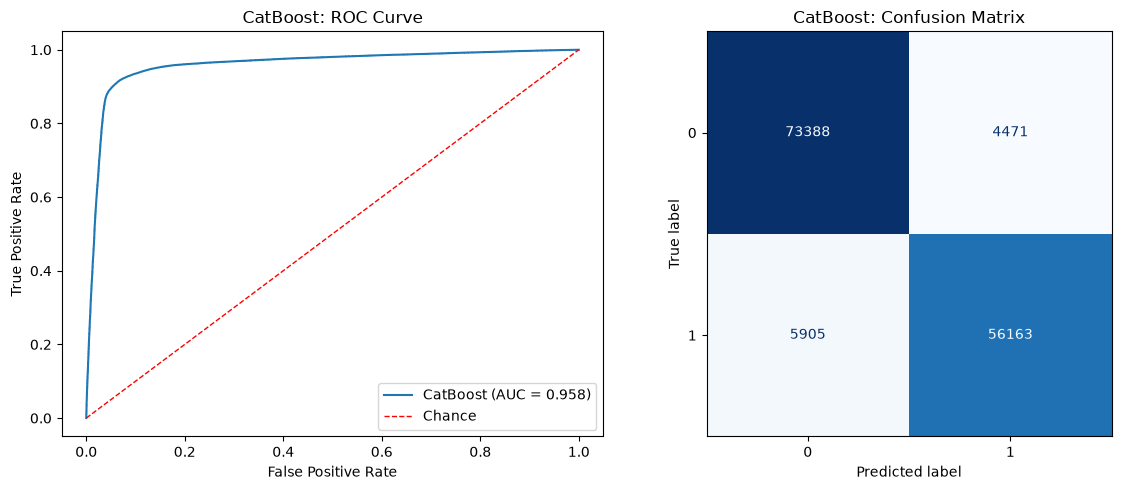

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['Age','Flight Distance','Inflight wifi service',...,'Customer Type', 'Type of Travel','Class']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,21
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remaind

In [26]:
evaluate('CatBoost', make_pipeline(
    CatBoostClassifier(
        iterations=1000,          
        learning_rate=0.03,
        depth=8,                  
        l2_leaf_reg=1.0,          
        min_data_in_leaf=20,      
        bootstrap_type='Bernoulli',
        subsample=0.8,            
        rsm=0.8,                  
        random_seed=RANDOM_STATE,
        thread_count=-1,          
        eval_metric='AUC',
        early_stopping_rounds=50,
        verbose=100
    )
))

#### 6.1.4 XGBoost

XGBoost                ROC-AUC = 0.9587   (4.6s)

Classification Report — XGBoost:
              precision    recall  f1-score   support

           0       0.93      0.94      0.93     77859
           1       0.93      0.90      0.92     62068

    accuracy                           0.93    139927
   macro avg       0.93      0.92      0.92    139927
weighted avg       0.93      0.93      0.93    139927



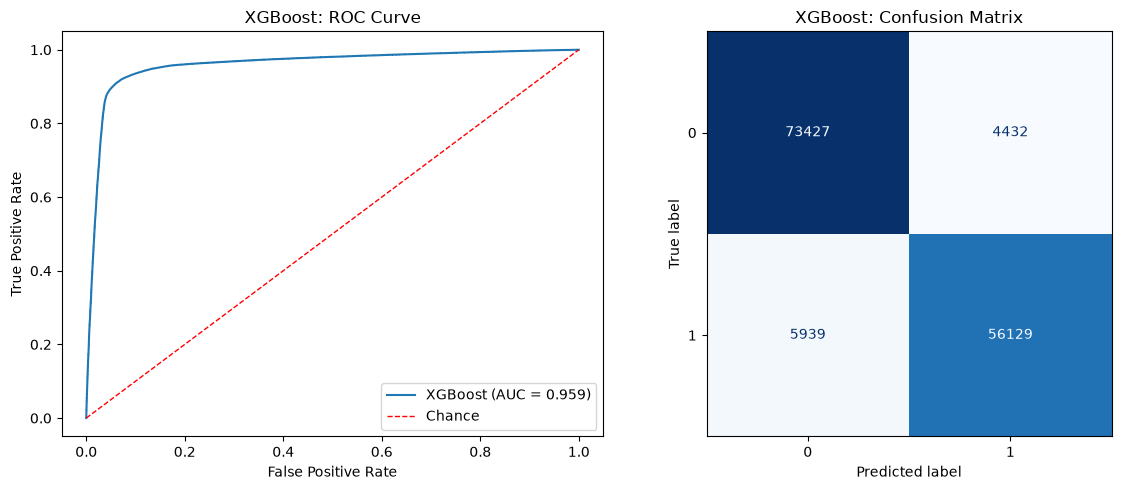

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['Age','Flight Distance','Inflight wifi service',...,'Customer Type', 'Type of Travel','Class']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,21
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remaind

In [27]:
evaluate('XGBoost', make_pipeline(
    XGBClassifier(
        n_estimators=1000,
        learning_rate=0.03,
        max_depth=6,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=1.0,
        eval_metric='auc',
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
))

### 6.2 Model Comparison

In [28]:
# Rank models by dev AUC
leaderboard = round(pd.DataFrame(results).T.sort_values('ROC_AUC', ascending=False),4)
leaderboard

,ROC_AUC,fit_seconds
XGBoost,0.9587,4.6152
CatBoost,0.9584,13.2458
LightGBM,0.9583,4.1303
Logistic Regression,0.9220,0.6400


In [29]:
# Best model
best_name = leaderboard['ROC_AUC'].idxmax()
best_model = models[best_name]

print(f'Selected model: {best_name}')

Selected model: XGBoost


### 6.3 Cross Validation

In [30]:
scoring = {
    'roc_auc': 'roc_auc',
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1'
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_results = cross_validate(best_model, X_train, y_train, cv=cv, scoring=scoring)

print(f"CV ROC-AUC:   {cv_results['test_roc_auc'].mean():.4f} ± {cv_results['test_roc_auc'].std():.4f}")
print(f"CV Accuracy:  {cv_results['test_accuracy'].mean():.4f} ± {cv_results['test_accuracy'].std():.4f}")
print(f"CV Precision: {cv_results['test_precision'].mean():.4f} ± {cv_results['test_precision'].std():.4f}")
print(f"CV Recall:    {cv_results['test_recall'].mean():.4f} ± {cv_results['test_recall'].std():.4f}")
print(f"CV F1:        {cv_results['test_f1'].mean():.4f} ± {cv_results['test_f1'].std():.4f}")

CV ROC-AUC:   0.9585 ± 0.0004
CV Accuracy:  0.9258 ± 0.0002
CV Precision: 0.9266 ± 0.0006
CV Recall:    0.9043 ± 0.0009
CV F1:        0.9153 ± 0.0003


### 6.4 Hyperparameter Tuning

In [31]:
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 300, 1500),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 20),   # ~ min_child_samples
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 0, 1),
        'reg_lambda': trial.suggest_float('reg_lambda', 0, 2),
        'gamma': trial.suggest_float('gamma', 0, 0.5),                      # ~ min_split_gain
        'scale_pos_weight': trial.suggest_float('scale_pos_weight', 1, 5),  # tune class-imbalance handling
        'random_state': RANDOM_STATE,
        'n_jobs': 1,           # single-threaded per fold
        'verbosity': 0,
        'tree_method': 'hist',
        'eval_metric': 'auc',
    }

    model = make_pipeline(XGBClassifier(**params))

    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)  # parallelism lives here instead
    return scores.mean()

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=50, n_jobs=1, show_progress_bar=True)  # show_progress_bar to confirm it's actually moving

[I 2026-10-04 12:00:04,108] A new study created in memory with name: no-name-4fe6db3f-9ee3-4a3c-86b2-c4dc7561bffc


  0%|          | 0/50 [00:00<?, ?it/s]

[I 2026-10-04 12:00:36,331] Trial 0 finished with value: 0.9578472883855541 and parameters: {'n_estimators': 1015, 'learning_rate': 0.041989373479108125, 'max_depth': 10, 'min_child_weight': 17, 'subsample': 0.7051372671804919, 'colsample_bytree': 0.7558461802483257, 'reg_alpha': 0.7388931844315764, 'reg_lambda': 1.0233765855884376, 'gamma': 0.33013377019521184, 'scale_pos_weight': 1.3450713489517439}. Best is trial 0 with value: 0.9578472883855541.
[I 2026-10-04 12:00:46,293] Trial 1 finished with value: 0.9576133781256342 and parameters: {'n_estimators': 534, 'learning_rate': 0.08327074401651581, 'max_depth': 4, 'min_child_weight': 13, 'subsample': 0.8169087864938959, 'colsample_bytree': 0.8672873808107913, 'reg_alpha': 0.22531289029097823, 'reg_lambda': 1.0296602678912155, 'gamma': 0.1743300495104464, 'scale_pos_weight': 4.26613552935313}. Best is trial 0 with value: 0.9578472883855541.
[I 2026-10-04 12:01:03,031] Trial 2 finished with value: 0.9579049032705328 and parameters: {'n_e

In [32]:
# Make final model
final_model = make_pipeline(XGBClassifier(**study.best_params, random_state=RANDOM_STATE, n_jobs=-1))
final_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['Age','Flight Distance','Inflight wifi service',...,'Customer Type', 'Type of Travel','Class']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,21
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remaind

## 7.0 Model Evaluation

Final Model            ROC-AUC = 0.9590   (11.0s)

Classification Report — Final Model:
              precision    recall  f1-score   support

           0       0.93      0.93      0.93     77859
           1       0.91      0.92      0.92     62068

    accuracy                           0.93    139927
   macro avg       0.92      0.92      0.92    139927
weighted avg       0.93      0.93      0.93    139927



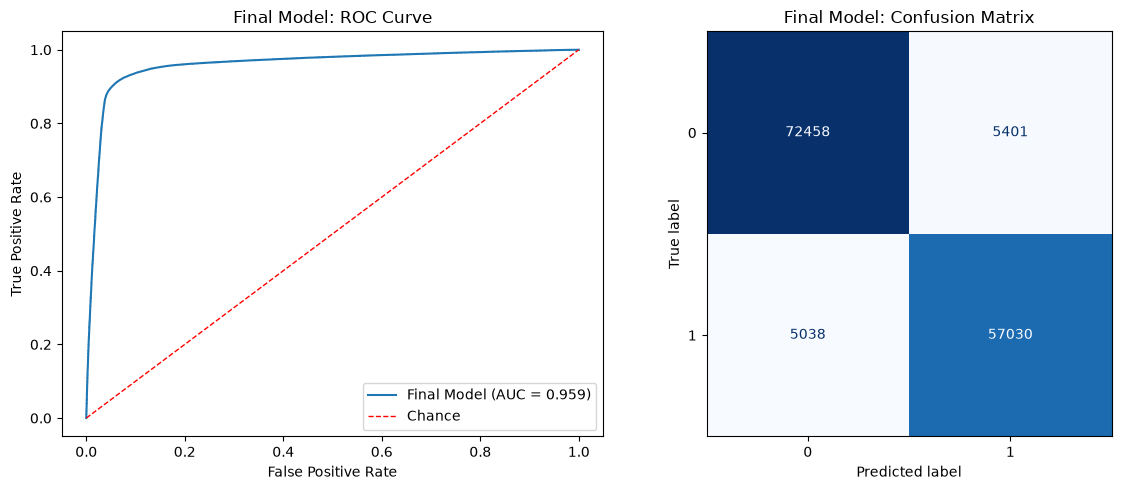

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['Age','Flight Distance','Inflight wifi service',...,'Customer Type', 'Type of Travel','Class']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,21
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remaind

In [33]:
evaluate('Final Model', make_pipeline(
    XGBClassifier(
        **study.best_params,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
))

### 7.1 Feature Importance

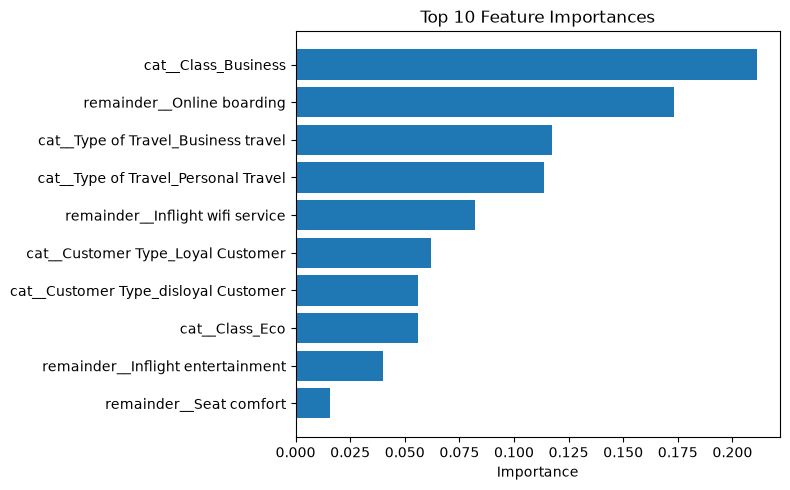

In [34]:
xgb_model = final_model.named_steps['model']
preprocessor_fitted = final_model.named_steps['preprocessor']

feature_names = preprocessor_fitted.get_feature_names_out()
importances = xgb_model.feature_importances_

imp_df = pd.DataFrame({'feature': feature_names, 'importance': importances})

# Keep only the top 10 by importance
imp_df = imp_df.sort_values('importance', ascending=False).head(10)
imp_df = imp_df.sort_values('importance', ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp_df['feature'], imp_df['importance'])
ax.set_xlabel('Importance')
ax.set_title('Top 10 Feature Importances')
plt.tight_layout()
plt.show()

## 8.0 Make Predictions

In [35]:
# Make predictions on test set
y_pred = final_model.predict_proba(test)[:, 1]

# Build submission file
submission = pd.DataFrame({
    'id': test.index,
    'satisfaction': y_pred
})

submission.to_csv(f'{OUTPUT_PATH}submission.csv', index=False)